# PPKS 08: Modulacije

***

Modulacija je proces u kojem se jedno ili više svojstava visokofrekvencijskog signala mijenja ovisno o signalu koji sadrži informaciju. Visokofrekvencijski signal kojem mijenjamo svojstva nazivamo **prijenosni signal** ili **nosilac** jer on „nosi” informaciju kroz komunikacijski kanal, a signal koji sadrži informaciju zovemo **modulacijski signal** ili **informacijski signal**. Signal koji dobijemo nakon modulacije zovemo **modulirani signal**.

Glavni cilj modulacije je učinkovitiji prijenos informacije kroz komunikacijski sustav. To se postiže tako da se pojas frekvencija informacijskog signala prenosi u više frekvencijsko područje pogodno za prijenos. Na taj način omogućuje se bolja organizacija frekvencijskog spektra i istovremeni rad velikog broja različitih komunikacijskih sustava bez međusobnog ometanja.

Na primjer, ljudski govor zauzima frekvencijsko područje približno od 300 Hz do 4 kHz. Kada bismo takav signal pokušali izravno odašiljati antenom, pojavljuje se praktičan problem. Za učinkovito zračenje antena mora imati dimenzije usporedive s valnom duljinom signala . Budući da su valne duljine na tako niskim frekvencijama vrlo velike, antene bi morale biti dimenzija nekoliko kilometara.
Na primjer, za $f=1 \text{ kHz}$ valna duljina je $\lambda = \frac{c}{f} = 300 \text{ km}$. 

Zato se signal govora modulira na visokofrekvencijski nosilac. Primjerice, ako radio postaja emitira na frekvenciji 100 MHz, informacija govora prenosi se na tu frekvenciju. Tada je valna duljina mnogo manja ($\lambda = 3\text{ m}$) pa antene mogu biti dimenzija od nekoliko desetaka centimetara do nekoliko metara.

Osim praktičnije veličine antena, modulacija omogućuje i dijeljenje frekvencijskog spektra između više korisnika. Primjer su različite AM i FM radio postaje koje emitiraju na različitim frekvencijama. Svaka postaja koristi vlastiti frekvencijski kanal, a prijamnik jednostavno odabire željenu frekvenciju.

Nakon što signal stigne do prijamnika, njegov se frekvencijski pojas ponovno premješta u osnovni pojas kako bi se iz moduliranoga izdvojio  informacijski signal. Taj postupak nazivamo **demodulacija**.

Sljedeći primjer prikazuje glavnu ideju: prebacivanje frekvencijskog pojasa informacijskog signala na više frekvencije. 

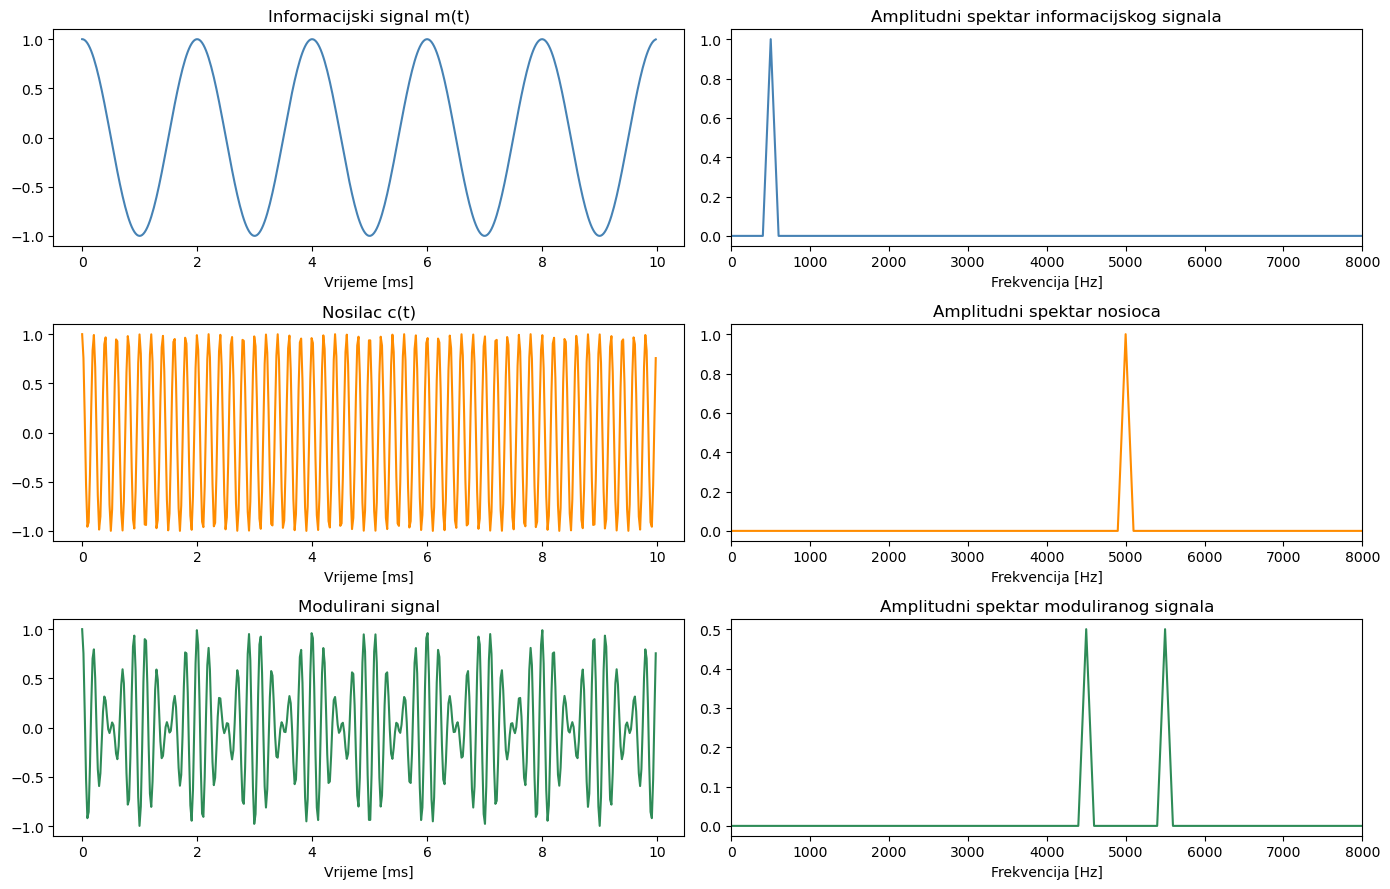

In [25]:
import numpy as np
import matplotlib.pyplot as plt

fs = 44100
fc = 5000
fm = 500
duration = 0.01

t = np.linspace(0, duration, int(fs * duration), endpoint=False)

m_t = np.cos(2 * np.pi * fm * t)
carrier = np.cos(2 * np.pi * fc * t)

s_mod = m_t * carrier

N = len(t)
freqs = np.fft.rfftfreq(N, 1/fs)

M_f = np.abs(np.fft.rfft(m_t)) / N * 2
C_f = np.abs(np.fft.rfft(carrier)) / N * 2
S_f = np.abs(np.fft.rfft(s_mod)) / N * 2

fig, axs = plt.subplots(3, 2, figsize=(14, 9))

axs[0,0].plot(t * 1000, m_t, color='steelblue')
axs[0,0].set_title('Informacijski signal m(t)')
axs[0,0].set_xlabel('Vrijeme [ms]')

axs[0,1].plot(freqs, M_f, color='steelblue')
axs[0,1].set_title('Amplitudni spektar informacijskog signala')
axs[0,1].set_xlabel('Frekvencija [Hz]')
axs[0,1].set_xlim(0, 8000)

axs[1,0].plot(t * 1000, carrier, color='darkorange')
axs[1,0].set_title('Nosilac c(t)')
axs[1,0].set_xlabel('Vrijeme [ms]')

axs[1,1].plot(freqs, C_f, color='darkorange')
axs[1,1].set_title('Amplitudni spektar nosioca')
axs[1,1].set_xlabel('Frekvencija [Hz]')
axs[1,1].set_xlim(0, 8000)

axs[2,0].plot(t * 1000, s_mod, color='seagreen')
axs[2,0].set_title('Modulirani signal')
axs[2,0].set_xlabel('Vrijeme [ms]')

axs[2,1].plot(freqs, S_f, color='seagreen')
axs[2,1].set_title('Amplitudni spektar moduliranog signala')
axs[2,1].set_xlabel('Frekvencija [Hz]')
axs[2,1].set_xlim(0, 8000)

plt.tight_layout()
plt.show()

***

Signal nosilac (engl. *carrier*) označavamo s $c(t)$ i najčešće ga modeliramo sinusoidom:

$$
c(t)=A_c \cos(2\pi f_c t)
$$

gdje je $A_c$ amplituda, a $f_c$ frekvencija nosioca.


Taj signal sam po sebi ne sadrži korisnu informaciju. Njegova je uloga omogućiti prijenos informacije kroz komunikacijski kanal tako da informacijski signal prenese u frekvencijsko područje pogodno za odašiljanje.
Ako informacijski signal označimo s $m(t)$, a njegovu najveću frekvencijsku komponentu s $f_{m\_max}$, u pravilu vrijedi da je frekvencija nosioca puno veća od frekvencija informacijskog signala:
$
f_c \gg f_{m\_max}
$.

Sinusni signal koristi se kao nosilac jer predstavlja najjednostavniji signal jedne frekvencije. Kao što smo napomenuli ranije na kolegiju, prema Fourierovoj analizi svaki signal može se prikazati kao zbroj sinusnih komponenti različitih frekvencija, amplituda i faza.
U frekvencijskom spektru takav signal sadrži dvije frekvencijske komponente (na $f_c$ i $-f_c$) pa je jednostavno promatrati kako informacijski signal utječe na njegova svojstva tijekom modulacije.

Budući da su sinus i kosinus međusobno samo fazno pomaknuti signali, u komunikacijskim sustavima se, po konvenciji, koristi kosinus kao standardni oblik zapisa jer za $t=0$ poprima maksimalnu vrijednost. 

Osim realnog zapisa, nosilac se često prikazuje i u kompleksnom obliku:
$
c(t)=\Re\{A_c e^{j(2\pi f_c t)}\}
$

U procesu modulacije moguće je mijenjati jedno ili više svojstava signala nosioca u ovisnosti o informacijskom signalu. Ta svojstva su:

- amplituda,
- frekvencija,
- cijela faza ($\phi(t)=2\pi f t$).

Ako se mijenja amplituda nosioca, govorimo o amplitudnoj modulaciji. Ako se mijenja frekvencija, radi se o frekvencijskoj modulaciji, a ako se mijenja cijela faza, govorimo o faznoj modulaciji.

Kod digitalnih modulacija te promjene više nisu kontinuirane, nego se odvijaju diskretno u skladu s digitalnim simbolima.



***

## Vrste modulacija

Modulacije dijelimo ovisno o tome je li informacijski signal analogan ili digitalan. **Analogne modulacije** mijenjaju neko svojstvo visokofrekvencijskog nosioca u skladu s kontinuiranim informacijskim signalom, dok je kod **digitalnih modulacija** informacijski signal niz diskretnih simbola. 

Ovisno o tome koje svojstvo signala nosioca mijenjamo, razlikujemo vrste modulacija. Kod analognih modulacija, ako mijenjamo amplitudu radimo **amplitudnu modulaciju** (AM; od engl. Amplitude Modulation), ako mijenjamo frekvenciju, **frekvencijsku modulaciju** (FM; od engl. Frequency Modulation), a ako mijenjamo fazu **faznu modulaciju** (PM; od engl. Phase Modulation). 

Kod digitalnih modulacija razlikujemo **diskretnu modulaciju amplitude** (ASK; od engl. Amplitude Shift Keying), **diskretnu modulaciju frekvencije** (FSK; od engl. Frequency Shift Keying) i **diskretnu modulaciju faze** (PSK, od engl. Phase Shift Keying). Posebno važni oblici fazne modulacije su diskretna modulacija faze s dvama (**BPSK**; od engl. Binary Phase Shift Keying) i četirima stanjima (**QPSK**; od engl. Quadrature Phase Shift Keying), koji se često koriste u digitalnim komunikacijskim sustavima. Uz njih se često koristi i kvadraturna amplitudna modulacija (**QAM**; od engl. Quadrature Amplitude Modulation), kod koje se istovremeno mijenjaju amplituda i faza nosioca. 

Od primjena, FM radio koristi **frekvencijsku modulaciju (FM)** za prijenos zvuka, AM radio koristi **amplitudnu modulaciju (AM)**, mobilne mreže koriste digitalne modulacije za prijenos podataka, Wi-Fi koristi složenije digitalne modulacije za brzi prijenos internetskog prometa (OFDM), a satelitske veze koriste modulacije prilagođene velikim udaljenostima i prisutnosti šuma. 

### Analogne modulacije

Informacijski signal $m(t)$ je kontinuiran (npr. zvuk, temperatura, napon).

| Modulacija | Oznaka | Promjena |
|------------|---------|----------------|
| Amplitudna modulacija | AM | amplituda $A(t)$ |
| Frekvencijska modulacija | FM | trenutna frekvencija $f_i(t)$ |
| Fazna modulacija | PM | trenutna faza $\phi(t)$ |

### Digitalne modulacije

Informacijski signal su diskretni simboli.

| Modulacija | Oznaka | Analogna paralela |
|------------|---------|-------------------|
| Diskretna modulacija amplitude | ASK | digitalna AM |
| Diskretna modulacija frekvencije | FSK | digitalna FM |
| Diskretna modulacija faze | PSK | digitalna PM |
| Kvadraturna amplitudna modulacija | QAM | kombinacija ASK + PSK |




***


# Amplitudna modulacija (AM)

Kod amplitudne modulacije amplituda nosioca $A_c$ mijenja se ovisno o informacijskom signalu, a frekvencija i faza ostaju konstantne.

Podsjećamo, nosilac zapisujemo kao:

$$
c(t)=A_c\cos(2\pi f_c t)
$$

Ako modulacijski signal označimo s $m(t)$, tada je modulirani signal:

$$
s(t)=A_c(1+k_am(t))\cos(2\pi f_ct)
$$

gdje je $k_a$ konstanta osjetljivosti modulatora.

Dakle, amplituda moduliranog signala se mijenja u vremenu ovisno o $m(t)$. Valja napomenuti da se pretpostavlja da su vrijednosti signala $m(t)$ između $-1$ i $1$, odnosno $|m(t)|\le 1$. Zato u izrazu imamo $+ 1$ jer želimo cijeli informacijski signal podignuti iznad $0$. Kad malo raspišemo izraz za $s(t)$ vidimo da naš informacijski signal zbog toga titra oko nosioca $c(t)$:

$$
s(t)=\underbrace{A_c\cos(2\pi f_ct)}_{c(t)}+A_ck_am(t)\cos(2\pi f_ct)
$$


***

Uzmimo za primjer informacijski signal jednostavnog sinusnog oblika amplitude $A_m$ i frekvencije $f_m$:
$
m(t)=A_m\cos(2\pi f_mt)
$

Tada je modulirani signal:

$$
s(t)=A_c(1+k_a\cdot A_m\cos(2\pi f_mt))\cos(2\pi f_ct)
$$

Ako to sada raspišemo imamo:

$
s(t)=A_c\cos(2\pi f_ct)+A_c k_a A_m\cos(2\pi f_mt)\cos(2\pi f_ct)
$

Primjenom 
$
\cos\alpha\cos\beta=\frac{1}{2}\left[\cos(\alpha+\beta)+\cos(\alpha-\beta)\right]
$
dobivamo:

$$
s(t)=A_c\cos(2\pi f_ct)+\frac{A_c k_a A_m}{2}\cos(2\pi(f_c+f_m)t)+\frac{A_c k_a A_m}{2}\cos(2\pi(f_c-f_m)t)
$$

Iz ovog izraza vidimo da modulirani signal u spektru sadrži tri frekvencijske komponente: $f_c,$ $f_c+f_m$ i $f_c-f_m$.




***

### Implementacija 

Pogledajmo primjer u kojem je informacijski signal sinusni signal frekvencije $f_m=500\text{ Hz}$ koji moduliramo pomoću nosioca frekvencije $f_c=10\text{ kHz}$.

U ovom primjeru jasno možemo vidjeti kako amplituda visokofrekvencijskog nosioca prati oblik informacijskog signala.
Drugim riječima, informacija nije sadržana u samim oscilacijama nosioca, nego u njegovoj ovojnici.
Osim vremenskog prikaza signala, analizirat ćemo i njegov frekvencijski spektar kako bismo vidjeli frekvencijske komponente koje nastaju modulacijom.





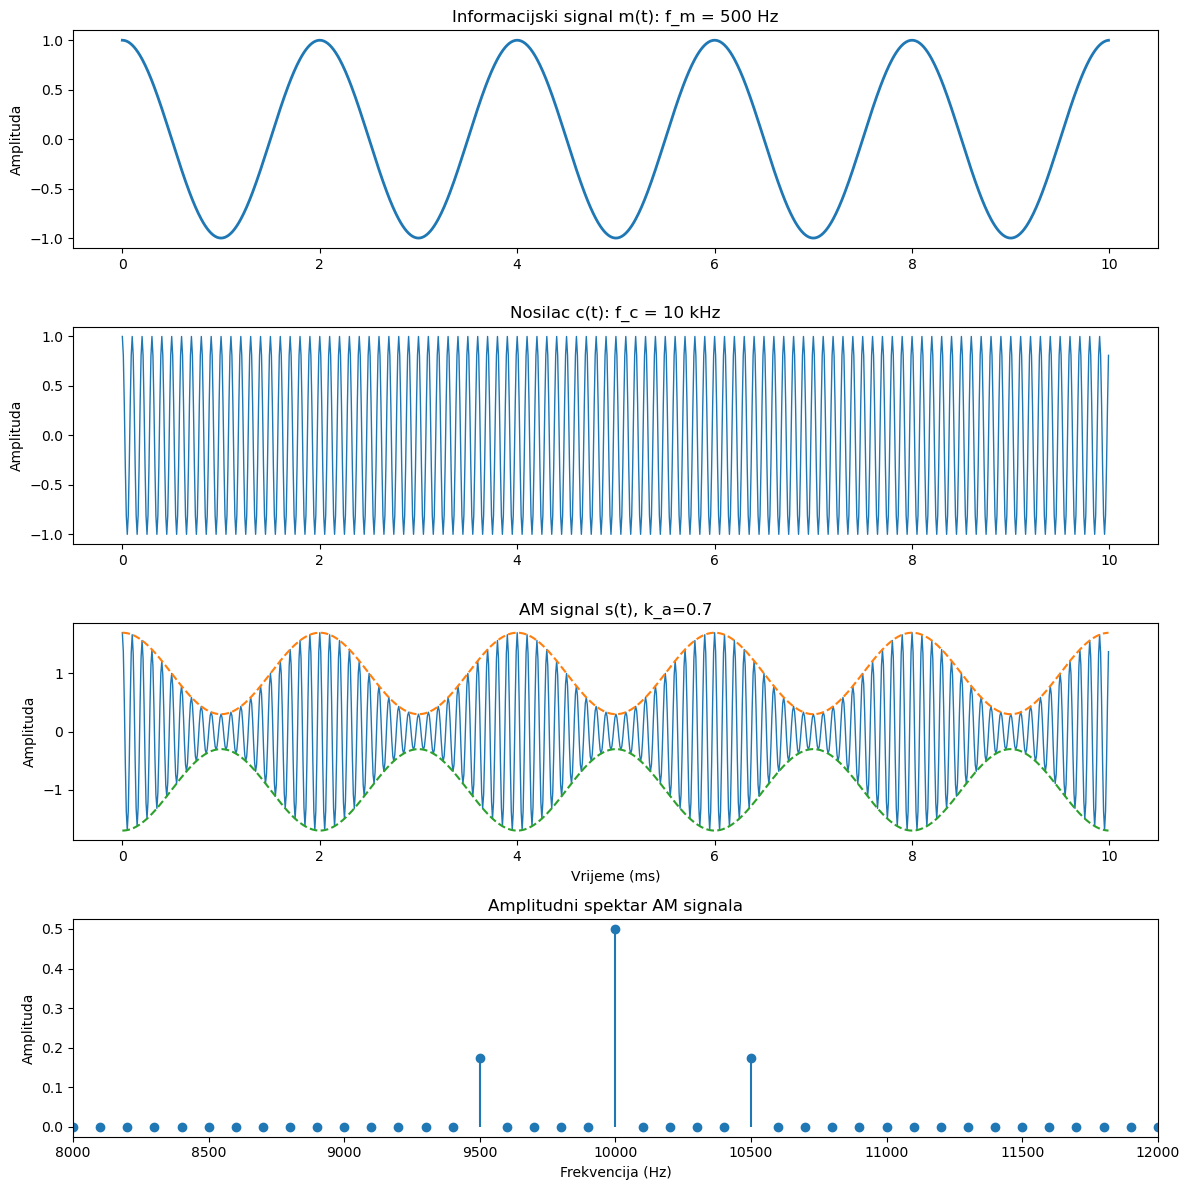

In [24]:
import numpy as np
import matplotlib.pyplot as plt

fs = 100_000
T = 0.01
t = np.linspace(0, T, int(fs*T), endpoint=False)

f_m = 500
f_c = 10_000
A_c = 1.0
ka = 0.7

m_t = np.cos(2*np.pi*f_m*t)
c_t = A_c*np.cos(2*np.pi*f_c*t)

s_t = A_c*(1 + ka*m_t)*np.cos(2*np.pi*f_c*t)

ovojnica_pos = A_c*(1 + ka*m_t)
ovojnica_neg = -A_c*(1 + ka*m_t)

N = len(s_t)
S_f = np.fft.fft(s_t)
freq = np.fft.fftfreq(N, 1/fs)

# samo pozitivne frekvencije
mask = freq >= 0
freq_pos = freq[mask]
S_mag = np.abs(S_f[mask])/N

# Prikaz
fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=False)

# Poruka
axes[0].plot(t*1000, m_t, linewidth=2)
axes[0].set_title('Informacijski signal m(t): f_m = 500 Hz')
axes[0].set_ylabel('Amplituda')

# Nosilac
axes[1].plot(t*1000, c_t, linewidth=1)
axes[1].set_title('Nosilac c(t): f_c = 10 kHz')
axes[1].set_ylabel('Amplituda')

# AM signal
axes[2].plot(t*1000, s_t, linewidth=1)
axes[2].plot(t*1000, ovojnica_pos, '--', linewidth=1.5)
axes[2].plot(t*1000, ovojnica_neg, '--', linewidth=1.5)
axes[2].set_title(f'AM signal s(t), k_a={ka}')
axes[2].set_ylabel('Amplituda')
axes[2].set_xlabel('Vrijeme (ms)')


# Spektar
axes[3].stem(freq_pos, S_mag, basefmt=" ")
axes[3].set_title('Amplitudni spektar AM signala')
axes[3].set_xlabel('Frekvencija (Hz)')
axes[3].set_ylabel('Amplituda')
axes[3].set_xlim(8000, 12000)

plt.tight_layout()
plt.show()

Amplitudna modulacija implementirana je izravno prema matematičkoj definiciji.
Najprije generiramo informacijski signal `m_t` koji predstavlja signal koji želimo prenijeti i nosilac `c_t` koji služi kao visokofrekvencijski signal za prijenos informacije.
Amplitudna modulacija ostvaruje se izrazom
`s_t = A_c*(1 + ka*m_t)*np.cos(2*np.pi*f_c*t)`

U tom izrazu član `(1 + k_a+m_t)` mijenja amplitudu nosioca u skladu s informacijskim signalom.

Konstanta $k_a$ određuje koliko snažno informacijski signal utječe na amplitudu nosioca.
Ako je vrijednost $k_a$ veća, promjene amplitude bit će izraženije, odnosno ovojnica signala bit će naglašenija.

Na taj način ostvarujemo osnovni princip amplitudne modulacije: informacija ne mijenja frekvenciju niti fazu nosioca, nego isključivo njegovu amplitudu.

### Što vidimo?

Na prvom grafu prikazan je informacijski signal frekvencije 500 Hz. Taj signal predstavlja poruku koju želimo prenijeti.
Na drugom grafu prikazan je nosilac frekvencije 10 kHz. Vidimo da se radi o znatno višoj frekvenciji od informacijskog signala.
Na trećem grafu prikazan je amplitudno modulirani signal. Vidi se da amplituda nosioca više nije konstantna, nego prati oblik informacijskog signala.

Isprekidana linija predstavlja ovojnicu signala. Upravo ta ovojnica sadrži informaciju koju i želimo prenijeti.
To znači da se pri demodulaciji mora izdvojiti ovojnica kako bismo rekonstruirali signal $m(t)$.

Na četvrtom grafu prikazan je amplitudni spektar moduliranog signala.
U spektru možemo uočiti tri frekvencijske komponente:
- Prva je frekvencija nosioca i ima najveću amplitudu ($\frac{A_c}{2}$):
$f_c=10\text{ kHz}
$
- Druga je frekvencija 
$
f_c-f_m=9500\text{ Hz}
$
- Treća je frekvencija
$
f_c+f_m=10500\text{ Hz}
$

Frekvencije oko nosioca nazivamo donjim (ispod $f_c$) i gornjim (iznad $f_c$) bočnim pojasevima.

Bočni pojasevi imaju manju amplitudu od nosioca i simetrično su raspoređeni oko njega. Budući da se radi o kosinusu, njihove su amplitude $\frac{A_c k_a A_m}{4}$.
Upravo se u bočnim pojasevima nalazi korisna informacija, dok nosilac sam po sebi ne nosi informaciju nego služi kao referenca za prijenos i demodulaciju. 

Ako informacijski signal zauzima frekvencijski pojas od $f_{min}$ do $f_{max}$, nakon amplitudne modulacije u spektru ćemo imati dva bočna pojasa: 
- gornji bočni pojas (engl. Upper Sideband, USB):
$f_c+f_{min} \rightarrow f_c+f_{max}$
- donji bočni pojas (engl. Lower Sideband, LSB):
$f_c-f_{max} \rightarrow f_c-f_{min}$

To znači da se ista informacija prenosi dvaput, odnosno da je širina frekvencijskog pojasa moduliranog signala dvostruko veća u odnosu na širinu frekvencijskog pojasa informacijskog. To je i jedan od najvećih nedostataka ove vrste modulacije. 

Kao rješenje se često koristi jednobočni pojas (engl. **single sideband, SSB**) koji šalje samo jedan bočni pojas, a drugi uklanja.
To se može ostvariti, između ostalog, filtriranjem. Najprije generiramo obični AM signal, a zatim filtrom uklanjamo jedan od bočnih pojaseva.
Za to je potreban filtar sa strmim prijelazom oko frekvencije nosioca što realizaciju čini tehnički zahtjevnijom.


### Odabir konstante osjetljivosti modulatora

Ako u prošlom primjeru postavimo `k_a = 1.0`, vidjet ćemo da u trenutku kad informacijski signal dosegne svoju najnižu vrijednost ($m(t)=-1$), amplituda moduliranog signala postaje jednaka nuli. 

To možemo vidjeti iz izraza za amplitudno modulirani signal:
$s(t)=A_c(1+k_am(t))\cos(2\pi f_ct)$

U tom slučaju vrijedi: $1\cdot(1+k_am(t))=1+1\cdot(-1)=0$ što znači da ovojnica dodiruje nulu (najniža vrijednost gornje ovojnice moduliranog signala). To se dogodilo jer smo za amplitudu informacijskog signala postavili $A_m=1$ pa je umnožak $k_a\cdot A_m=1$. 

Taj nam umnožak, koji zovemo **indeks modulacije** i označavamo s $\mu=k_a\cdot A_m$, određuje koliki dio amplitude nosioca sudjeluje u prijenosu informacije. Cilj je da bude što bliže $1$ jer je u tom slučaju amplituda nosioca maksimalno iskorištena, ali treba biti oprezan s postavljanjem parametra $k_a$ jer u slučaju $\mu>1$ dolazi do **premodulacije** (engl. overmodulation) koja uzrokuje izobličenje moduliranog signala što otežava demodulaciju. Zato kod amplitudne modulacije želimo održati 

$$
\mu\leq1
$$

Utjecaj premodulacije vidimo na sljedećem primjeru.




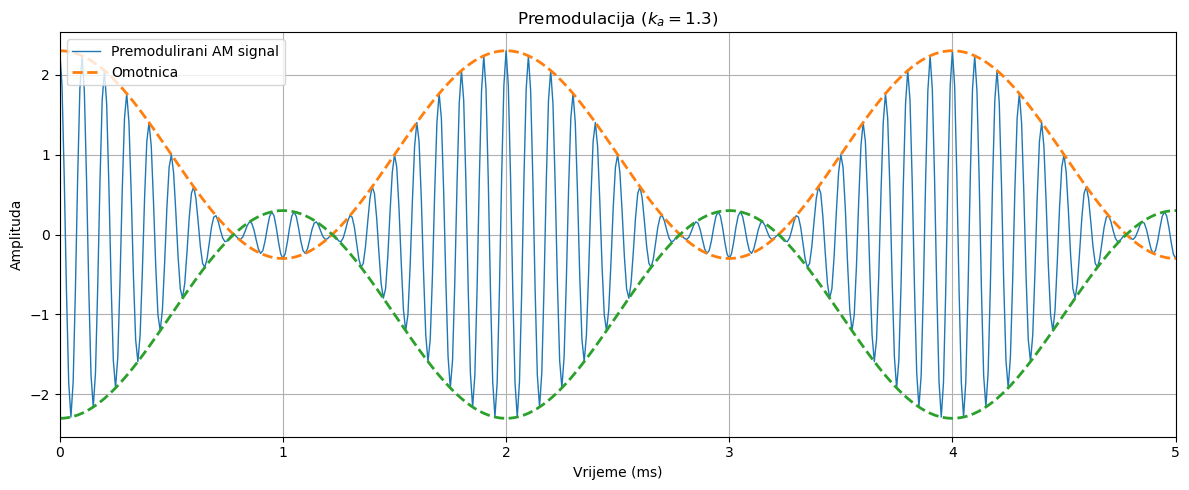

In [23]:
import numpy as np
import matplotlib.pyplot as plt

fs = 100_000
T = 0.01
t = np.linspace(0, T, int(fs * T), endpoint=False)

f_m = 500
f_c = 10_000
A_c = 1.0
k_a = 1.3

m_t = np.cos(2 * np.pi * f_m * t)

s_t = A_c * (1 + k_a * m_t) * np.cos(2 * np.pi * f_c * t)

ovojnica_pos = A_c * (1 + k_a * m_t)
ovojnica_neg = -A_c * (1 + k_a * m_t)

plt.figure(figsize=(12, 5))

plt.plot(t * 1000, s_t, linewidth=1, label='Premodulirani AM signal')
plt.plot(t * 1000, ovojnica_pos, '--', linewidth=2, label='Ovojnica')
plt.plot(t * 1000, ovojnica_neg, '--', linewidth=2)

plt.title(f'Premodulacija ($k_a={k_a}$)')
plt.xlabel('Vrijeme (ms)')
plt.ylabel('Amplituda')
plt.xlim(0, 5)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Demodulacija amplitudno moduliranog signala

Demodulacija je postupak izdvajanja informacije iz moduliranog signala.
Za amplitudnu modulaciju znamo da se informacijski signal $m(t)$ nalazi unutar njegove amplitude.
To znači da je za demodulaciju dovoljno izdvojiti ovojnicu moduliranog signala. Ovojnicom zovemo zamišljenju krivulju koja dodiruje signal u svakoj periodi u jednoj točki, približno u vršnoj vrijednosti.
Postupak izdvajanja ovojnice zovemo **detekcija ovojnice** (engl. *envelope detection*).

Ako pogledamo amplitudno modulirani signal, vidimo da se njegova amplituda mijenja u vremenu i da prati oblik informacijskog signala.
Odnosno, ovojnica signala ima oblik:
$
A(t)=A_c(1+k_am(t))
$.

$A(t)$ je trenutna amplituda moduliranog signala. Do nje možemo doći tako da promatramo modulirani signal u kompleksnoj ravnini. Budući da se radi o realnom signalu, moramo ga prikazati u kompleksnom obliku. Kompleksni zapis realnog signala zovemo **analitički signal**. 






